# Gaussian experiment, from formulas to code

This notebook follows the six stages: compare DFM (MLP) and DFM (Gaussian + MLP),
freeze DFM (Gaussian + MLP), train CDG-ML (Guo et al., 2026; no refinements)
and Refined CDG-ML (all five refinements), then generate conditional returns and compare
five sources: the conditional ground truth, DFM rejection sampling, CDG-ML, Refined
CDG-ML, and no guidance, the last three with an exact final sampling step.
The method and its assumptions are documented in [METHODS.md](METHODS.md).

Use $R$ for clean population returns, $s$ for forward OU noising time,
$t$ for elapsed generation time, and $\tau=T-t_0$. The ambient generated state is
$X_t$ and the reduced conditioning state is $Y_t=G_tX_t$.

**Sources.** The DFM (forward process, score network, training objective,
and sampler) follows Chen et al. (2025). The Gaussian + MLP network and market-calibrated
Gaussian population are project adaptations. The terminal-event
probability $H$, its Doob guidance, CDG-ML and the guidance scale follow
Guo et al. (2026).

## Configuration

The notebook defaults to `MODE="standard"`; set `MODE="smoke"` for a shorter
execution. Both modes compare the two DFM networks on the same draws and condition
DFM (Gaussian + MLP) at the 5% and 1% event levels. The effective configuration is
displayed by the code below. Both modes need the locally cleaned market panel.

| Setting | Notebook smoke | Notebook standard (default) |
| --- | ---: | ---: |
| Assets / factors | 12 / 8 | 500 / 8 |
| DFM train / validation / evaluation observations | 2,048 / 512 / 512 | 2,500 / 750 / 3,000 |
| DFM epochs / hidden widths | 15 / (32, 32) | 1,000 / (64, 64) |
| Integration steps | 100 | 400 |
| H train / validation / test trajectories | 2,048 / 1,024 / 1,024 | 40,000 / 2,000 / 2,000 |
| H epochs / hidden widths (validation every 157 optimizer steps) | 10 / (64, 64) | 50 / (64, 64) |
| Guided and ground-truth samples per source | 512 | 3,000 |
| Accepted samples per DFM rejection stream | 128 | 1,000 |
| Proposal cap per DFM rejection stream (5% / 1%) | 10,240 / 51,200 | 80,000 / 400,000 |


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict, replace
import sys
import time

import numpy as np
import pandas as pd
from scipy.stats import kstest
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "DFM.py").exists():
    raise RuntimeError("Run this notebook with the repository as working directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from reference import FrozenDFMReference
from sampling import generate_samples

In [2]:
from synthetic_benchmark.configuration import Config, write_json
from synthetic_benchmark.reporting import DFM_LABELS

In [3]:
import os
# Set to a saved run to keep its DFMs fixed; None trains new DFMs.
FROZEN_DFM_RUN = os.environ.get("SYNTHETIC_FROZEN_DFM_RUN")
MODE = "standard"  # smoke reduces dimensions and both DFM and H training budgets.
CONFIG_OVERRIDES = {
    # Gaussian factor population calibrated on a cohort of real stocks (section 1).
    "population": "market",
    "market_panel": "artifacts/market_data_cleaning/20261029T104817954744Z/train_complete.npz",
    "d": 12 if MODE == "smoke" else 500,
    "k": 8,
    # About as many observations as the panel's 2,516 training and 756 validation days.
    "n_train": 2_048 if MODE == "smoke" else 2_500,
    "n_val": 512 if MODE == "smoke" else 750,
    # Selected using observed validation returns; the objective is explained below.
    "dfm_initialization": "pca",
    "dfm_time_sampling": "log_balanced",
    "dfm_loading_lr_scale": 0.1,
    "dfm_loading_warmup_epochs": 100,
    "lr": 1e-3,
    "torch_threads": 4,
    # "seeds": (42,),
    # "n_eval": 3_000, "dfm_epochs": 1_000, "steps": 400,
    # "T": 8.0, "t0": 0.005, "width": 64,
    # "batch": 256, "device": "cpu",
}
CONFIG = replace(Config.preset(MODE), **CONFIG_OVERRIDES)
# Both DFMs are trained on the same draws; guidance runs on DFM (Gaussian + MLP).
DFM_NETWORKS = ("mlp", "gaussian_mlp")
OUTPUT = ROOT / "artifacts" / "synthetic_unconditional_benchmark" / (
    MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
display(pd.Series(asdict(CONFIG), name="Effective DFM configuration").to_frame())
print(f"DFM training: {CONFIG.dfm_epochs:,} epochs per seed, for "
      + " and ".join(DFM_LABELS[network] for network in DFM_NETWORKS))
print("Artifacts:", OUTPUT)

,Effective DFM configuration
mode,standard
d,500
k,8
seeds,"(42,)"
cases,"(gaussian,)"
n_train,2500
n_val,750
n_eval,3000
dfm_epochs,1000
steps,400


DFM training: 1,000 epochs per seed, for DFM (MLP) and DFM (Gaussian + MLP)
Artifacts: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T142439318443Z


## 1. Construct the synthetic population

We generate a Gaussian factor population calibrated on a cohort of real stocks. The Gaussian specification provides analytical unconditional and portfolio-event-conditional benchmarks for assessing both the fitted DFM and the additional conditioning procedure.

The default standard experiment uses $d=500,k=8$, calibrated on 500 of the locally cleaned panel's 800 stocks and 2,516 training days (2010–2019). It draws 2,500 training and 750 validation observations, close to the real panel's sample sizes. Smoke mode uses $d=12,k=8$ with reduced training budgets.

Choose the stock cohort once, with this project's cohort seed 500. Standardize each stock's training returns to obtain $z$, and let $B$ contain the leading $k$ orthonormal eigenvectors of its sample correlation matrix, with eigenvalues $\lambda_j$. Define
$$
B^\top B=I_k,\qquad
D_i=\widehat{\operatorname{Var}}\!\left(z_i-(BB^\top z)_i\right),\qquad
S_{jj}=\lambda_j-\sum_i B_{ij}^2D_i,\quad S_{ij}=0\ (i\ne j).
$$
This preserves the variance along each retained real principal-component direction: $b_j^\top\Sigma b_j=\lambda_j$. With heterogeneous $D_i$, the population's eigenvectors need not equal those of the real correlation matrix.

Hold these parameters fixed across independent training, validation, and evaluation draws:
$$
F\sim\mathcal N(0,S),\quad
\varepsilon\sim\mathcal N(0,\operatorname{diag}(D)),\quad F\perp\varepsilon,\quad
R=BF+\varepsilon,
$$
$$
\mu=0,\qquad
\Sigma=BSB^\top+\operatorname{diag}(D).
$$

The synthetic returns are in standardized-return units; the Gaussian draws do not reproduce the heavy tails of the real stocks.

The equal-weight portfolio and population event remain
$$
w=\frac{\mathbf1}{d},\quad P=w^\top R\sim\mathcal N(a,v),\quad
 a=w^\top\mu,\quad v=w^\top\Sigma w,\quad
 C_q=a+\sqrt v\,\Phi^{-1}(q),\quad q\in\{0.05,0.01\}.
$$

The DFM receives returns only and learns its own $V$.

This is a market-calibrated Gaussian testbed, rather than a replication of the synthetic population or U-Net experiments of Chen et al. (2025). The local market panel is required to reconstruct it; its path, checksum, and cohort seed are recorded with checkpoints.


In [4]:
from synthetic_benchmark.unconditional import population_for_config

population = population_for_config(CONFIG)
population_mean, population_covariance = population.moments()
construction = population.construction
print(f"Calibrated on {construction['panel_days']:,} training days of {population.d} of the panel's "
      f"{construction['panel_stocks']} stocks (cohort seed {construction['population_seed']}); k={population.k}")
factor_variances = np.diag(population.S[0])
display(pd.DataFrame({
    "eigenvalue of the real correlation matrix": construction["eigenvalues"][:population.k],
    "factor variance S_jj": factor_variances,
    "share of total variance": factor_variances / np.trace(population_covariance),
    "S_jj / mean residual variance": factor_variances / population.D.mean(),
}).rename_axis("factor"))
display(pd.Series({
    "residual_variance_mean": population.D.mean(),
    "residual_variance_min": population.D.min(),
    "residual_variance_max": population.D.max(),
    "orthonormality_error": np.linalg.norm(population.B.T @ population.B - np.eye(population.k)),
    "portfolio_mean": population.w @ population_mean,
    "portfolio_variance": population.w @ population_covariance @ population.w,
    "portfolio_5pct_threshold": population.threshold(0.05),
    "portfolio_1pct_threshold": population.threshold(0.01),
}, name="Population truth").to_frame())

Calibrated on 2,516 training days of 500 of the panel's 800 stocks (cohort seed 500); k=8


,eigenvalue of the real correlation matrix,factor variance S_jj,share of total variance,S_jj / mean residual variance
factor,,,,
0,171.571516,171.070780,0.344840,310.876217
1,17.805752,17.418814,0.035112,31.654119
2,9.192001,8.754161,0.017646,15.908389
3,7.108196,6.593085,0.013290,11.981201
4,5.931863,5.432447,0.010951,9.872045
5,5.310737,4.815696,0.009707,8.751263
6,4.132649,3.580499,0.007217,6.506617
7,3.804366,3.278448,0.006609,5.957719


,Population truth
residual_variance_mean,5.502858e-01
residual_variance_min,1.674803e-01
residual_variance_max,9.881488e-01
orthonormality_error,2.571159e-15
portfolio_mean,0.000000e+00
portfolio_variance,3.273480e-01
portfolio_5pct_threshold,-9.410921e-01
portfolio_1pct_threshold,-1.331004e+00


## 2. Train and sample the unconditional DFM

We compare **DFM (MLP)** and **DFM (Gaussian + MLP)** on the same return draws.
Both use two training refinements to improve the unguided DFM's approximation of the
return distribution, particularly its covariance structure:

1. **Observation-based initialization and staged loading updates.** The loading matrix determines which directions of joint return variation the factor network sees. Starting from random directions makes the network learn this representation at the same time as it learns the score. We instead initialize the loadings with the principal components of the training returns and initialize the idiosyncratic variances from the remaining variation, as in the principal-components factor estimate of Bai (2003). We first hold the loadings fixed so the other parameters can adapt to these coordinates, then update them at a smaller learning rate. This provides an informed starting point while allowing the representation to adjust during score learning.

2. **Log-spaced noising times and noise-variance-weighted score matching.** Uniform time sampling devotes few training examples to the small noising times that correspond to the final stages of generation, where the model must recover the detailed return distribution. Sampling times on a logarithmic scale gives these small times more coverage. At the same time, the denoising target grows as the noise level decreases; weighting the squared error by the noise variance counteracts this growth. Together, these choices aim to improve score learning across noise levels without allowing the scale of the low-noise target to dominate the loss. The noise-variance weight follows Song et al. (2021) and Ho et al. (2020), and log-spaced noise levels appear in Song et al. (2019) and Karras et al. (2022). Together they replace the uniform time weight of Chen et al. (2025).

The notebook combines refinements (1) and (2) for both networks; their effective
configuration is displayed above.

For clean returns $R$, the forward OU corruption of Chen et al. (2025) is

$$
R_s=\alpha_s R+\sqrt{h_s}\,\xi,\qquad
\alpha_s=e^{-s/2},\quad h_s=1-e^{-s},\quad \xi\sim N(0,I_d).
$$

The learned score in [`FactorScoreNetwork.forward`](NeuralNets.py) is the
factor-aware score network of Chen et al. (2025):

$$
s_\theta(r,s)=\alpha_s D_s Vg_\zeta(V^\top D_s r,s)-D_sr,\qquad
D_s=\operatorname{diag}(h_s+\alpha_s^2 c_i)^{-1}.
$$

Here $V\in\mathbb R^{d\times k}$, $c_i=2\operatorname{sigmoid}(c_{\rm raw,i})$,
and the two-hidden-layer ReLU MLP $g_\zeta$ are learned jointly.
The fitted $V,c$ need not equal the population $B,D$. Chen et al. analyse this
form but use a 2D U-Net with approximately one billion parameters in their experiments
(Appendices D and E); here the theoretical form is implemented directly as **DFM (MLP)**.

**DFM (Gaussian + MLP)** keeps this outer score form and replaces only the inner map by
an exact Gaussian factor posterior mean plus an MLP correction. With
$M_s=V^\top D_sV$, $z=V^\top D_sr$, and a trainable factor prior $F\sim N(m,S)$,
$$
g(z,s)=m+(I_k+\alpha_s^2SM_s)^{-1}S\alpha_s(z-\alpha_sM_sm)
+g_\zeta(z,s).
$$
The Gaussian part supplies the affine
posterior mean, leaving the MLP to learn departures from it. This is a project
substitution for the paper's empirical architecture, favored by this Gaussian
population; it does not establish recovery of heavy tails. The two networks have
9,820 and 9,892 parameters, respectively, in the standard configuration.


In [5]:
from synthetic_benchmark.unconditional import (
    initialize_unconditional_run, prepare_unconditional_case, dfm_folder_name,
    fit_and_save_dfm, evaluate_unconditional_samples,
    save_unconditional_case, save_unconditional_summary,
)

### Unconditional sampling

After fitting, [`generate_samples`](sampling.py) approximates the reverse-time SDE
of Chen et al. (2025),

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)\right]dt+dW_t,
\qquad X_0\sim N(0,I_d),\quad 0\le t\le\tau.
$$

With $\Delta t=\tau/J$, it applies Euler–Maruyama:
$X_{j+1}=X_j+[X_j/2+s_\theta(X_j,T-t_j)]\Delta t+
\sqrt{\Delta t}\xi_j$.
Finite $T$, positive $t_0$, fitting error, and discretization all affect agreement
with the clean Gaussian population.


In [6]:
from synthetic_benchmark.reporting import (
    plot_dfm_validation, plot_dfm_comparison, UNCONDITIONAL_METRIC_LABELS, TRUTH_REFERENCE_LABEL,
)

### Execute training and evaluation


In [7]:
if tuple(CONFIG.cases) != ("gaussian",):
    raise RuntimeError("Stale simulation configuration: restart the kernel, reload this Gaussian notebook, and run all cells in order.")

initialize_unconditional_run(OUTPUT, CONFIG)
if FROZEN_DFM_RUN:
    from synthetic_benchmark.conditional import reuse_frozen_unconditional_run
    metrics, numeric = reuse_frozen_unconditional_run(FROZEN_DFM_RUN, OUTPUT, CONFIG, DFM_NETWORKS)
else:
    started = time.perf_counter()
    rows = []
    case = "gaussian"
    for seed in CONFIG.seeds:
        for network in DFM_NETWORKS:
            # The same seed gives both networks the same training, validation and evaluation draws.
            config = replace(CONFIG, dfm_network=network)
            folder, streams, pop = prepare_unconditional_case(OUTPUT, config, case, seed)
            train = pop.sample(config.n_train, streams.np("train"))
            val = pop.sample(config.n_val, streams.np("validation"))
            truth = pop.sample(config.n_eval, streams.np("truth"))
            truth2 = pop.sample(config.n_eval, streams.np("truth2"))

            model, history, selected, fit_seconds = fit_and_save_dfm(
                train, val, config, streams, pop, case, folder,
            )
            reference = FrozenDFMReference(model)
            gen_start = time.perf_counter()
            generated = generate_samples(
                reference, config.n_eval, num_steps=config.steps,
                generator=streams.torch("generated", config.device),
            ).cpu().numpy()
            generation_seconds = time.perf_counter() - gen_start

            result, baseline = evaluate_unconditional_samples(
                generated, truth, truth2, pop, reference, config, case, seed,
                fit_seconds, generation_seconds,
            )
            rows.extend([result, baseline])
            save_unconditional_case(folder, case, generated, truth, truth2, pop, result, baseline)
    metrics, numeric = save_unconditional_summary(rows, OUTPUT, started)

Running DFM (MLP), seed=42, d=500


Assets: 500; population factors: 8; DFM factors: 8


Running DFM (Gaussian + MLP), seed=42, d=500


Assets: 500; population factors: 8; DFM factors: 8


Finished: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T142439318443Z


In [8]:
columns = ["covariance_error", "sliced_w1", "portfolio_ks", "leading_factor_variance_ratio",
           "factor_variance_ratio_min", "factor_variance_ratio_max", "residual_variance_ratio",
           "event_0.05", "event_0.01", "fit_seconds"]
display(metrics.set_index("method")[columns].T.rename_axis(None, axis=1)
        .rename(index=UNCONDITIONAL_METRIC_LABELS, columns={"truth-vs-truth": TRUTH_REFERENCE_LABEL}).round(4))

,DFM (MLP),Independent truth draw (noise),DFM (Gaussian + MLP)
Covariance error,0.1924,0.0536,0.0738
Sliced W1,0.0784,0.0339,0.0316
Portfolio KS,0.0763,0.0310,0.0220
Largest factor: variance ratio,0.8171,1.0245,0.9708
All factors: smallest variance ratio,0.8171,0.9772,0.9522
All factors: largest variance ratio,1.0014,1.0296,1.0046
Residual variance ratio,1.0250,1.0015,1.0184
Share below the 5% quantile,0.0453,0.0520,0.0457
Share below the 1% quantile,0.0020,0.0120,0.0083
Training time (s),45.7452,NaN,107.5512


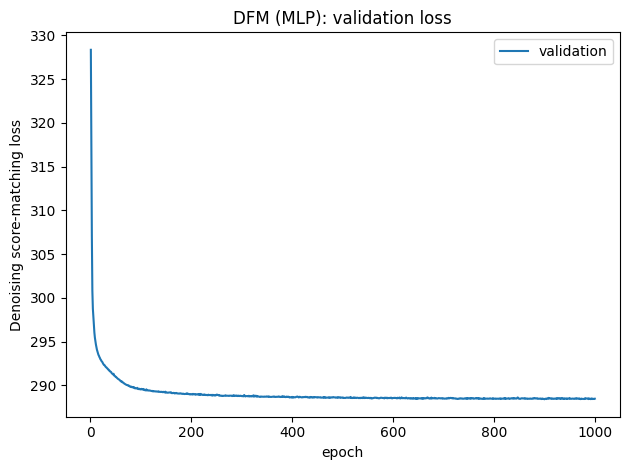

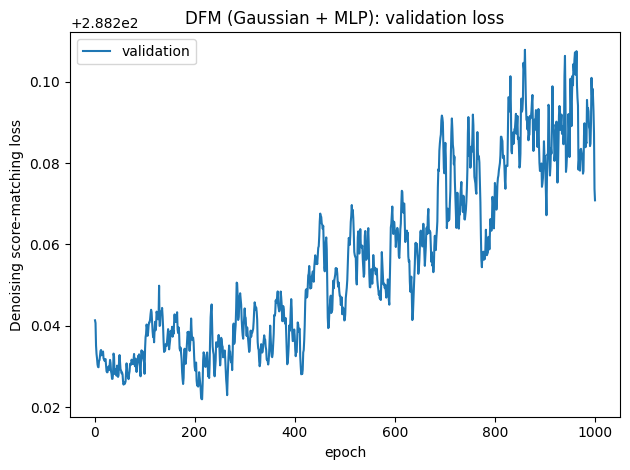

In [9]:
for network in DFM_NETWORKS:
    plot_dfm_validation(OUTPUT / dfm_folder_name("gaussian", CONFIG.seeds[0], network), DFM_LABELS[network])

### Monte Carlo reference level


,DFM (MLP),DFM (Gaussian + MLP),Independent truth draw (noise)
Covariance error,0.1924,0.0738,0.0536
Sliced W1,0.0784,0.0316,0.0339
Portfolio KS,0.0763,0.0220,0.0310
Largest factor: variance ratio,0.8171,0.9708,1.0245
All factors: smallest variance ratio,0.8171,0.9522,0.9772
All factors: largest variance ratio,1.0014,1.0046,1.0296
Share below the 5% quantile,0.0453,0.0457,0.0520
Share below the 1% quantile,0.0020,0.0083,0.0120


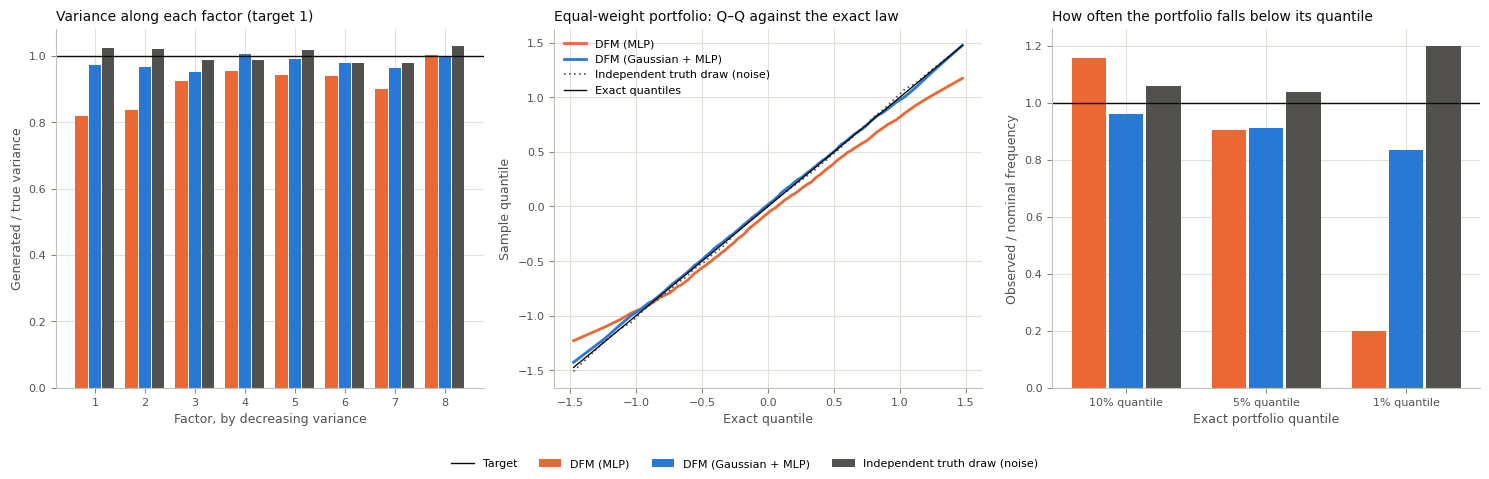

1117

In [10]:
primary = metrics.loc[
    (metrics.case == "gaussian") & (metrics.seed == CONFIG.seeds[0])
].set_index("method")
report_metrics = ["covariance_error", "sliced_w1", "portfolio_ks", "leading_factor_variance_ratio",
                  "factor_variance_ratio_min", "factor_variance_ratio_max", "event_0.05", "event_0.01"]
recovery_comparison = (
    primary.loc[[*(DFM_LABELS[n] for n in DFM_NETWORKS), "truth-vs-truth"], report_metrics].T
    .rename(index=UNCONDITIONAL_METRIC_LABELS, columns={"truth-vs-truth": TRUTH_REFERENCE_LABEL})
    .rename_axis(None, axis=1)
)
display(recovery_comparison.round(4))
generated_samples = {}
for network in DFM_NETWORKS:
    with np.load(OUTPUT / dfm_folder_name("gaussian", CONFIG.seeds[0], network) / "unconditional_samples.npz") as saved:
        generated_samples[network] = saved["generated"]
        truth_reference = saved["truth2"]
plot_dfm_comparison(generated_samples, truth_reference, population, OUTPUT / "dfm_comparison.png")
text = (
    f"Market-calibrated benchmark: seed {CONFIG.seeds[0]}, d={CONFIG.d}, k={CONFIG.k}, "
    f"{CONFIG.n_train:,} training observations.\n\n"
    + "```text\n" + recovery_comparison.to_string() + "\n```\n\n"
    + "The independent truth comparison describes Monte Carlo variability; factor variance ratios have target 1.\n"
)
(OUTPUT / "conclusions.md").write_text(text)

## 3. Freeze the DFM and construct conditioning coordinates

[`FrozenDFMReference(model)`](reference.py) deep-copies the trained DFM (Gaussian + MLP) score,
freezes every parameter, and fixes its time settings. Input derivatives remain
available, so freezing the DFM does not prevent guidance differentiation.

Let $s=T-t$, $\Lambda_s=D_s^{-1}$, and

$$
\ell_t=\frac{\alpha_s}{\alpha_{t_0}}D_s\Lambda_{t_0}w,
\qquad
G_t=\begin{bmatrix}V^\top D_s\\\ell_t^\top\end{bmatrix},
\qquad
Y_t=G_tX_t=(Z_t,U_t).
$$

At $t=\tau$, $s=t_0$ and $D_{t_0}\Lambda_{t_0}=I$, hence
$\ell_\tau=w$ and $U_\tau=w^\top X_\tau$. This keeps the entire portfolio event,
including the residual return contribution. Earlier $U_t$ generally differs from
$w^\top X_t$.

## 4. Compare CDG-ML and Refined CDG-ML

The continuous-time target is the terminal-event probability of Guo et al. (2026),
written in the reduced coordinates:

$$
H(t,y)=P(U_\tau\le C\mid Y_t=y),\qquad
H(\tau,y)=\mathbf1\{u\le C\}.
$$

The notebook trains two H models on the **same frozen DFM and the same training,
validation, and test trajectories**. Here **CDG-ML** is the martingale-loss method of Guo et al. (2026):
it regresses the terminal event indicator on $(t,Y_t)$
along unguided paths of the frozen pretrained model with a squared loss, then
guides with $\nabla\log H_\phi$. We apply it to the reduced coordinates $Y_t$ rather
than the full state, without any of the five refinements: unstandardized coordinates, normalized time only,
binary terminal labels at every preterminal time, ordinary interval weights
$\omega_j$, and MSE (Brier) loss. CDG-ML uses every stored time per trajectory.
In standard mode, both variants use the same hidden widths, learning rate and training budget:
40,000 training trajectories for 50 epochs, validated every 157 optimizer steps. This
is displayed in the configuration above. The five refinements and their assumptions
are detailed in [METHODS.md](METHODS.md). Each variant selects its own checkpoint using its
configured validation objective. Their validation
loss values have different meanings (MSE versus BCE).

Guo et al. (2026) note that an accurate $H_\phi$ need not give an accurate
$\nabla\log H_\phi$, and propose a covariation-based loss (CDG-MCL) that learns
$\nabla H$ separately. The refinements below address the same problem
differently; CDG-MCL is not implemented here.

**Refined CDG-ML** adds the following five refinements:

1. **Standardization of the reduced coordinates.** We standardize each reduced coordinate using time-dependent means and standard deviations estimated from the training trajectories. This prevents coordinates with larger magnitudes from dominating the network inputs and helps limit saturation of the Tanh activations. Standardization remains inside the network’s computational graph, preserving the chain rule used for guidance.

2. **An additional temporal input.** Alongside normalized time, we provide the log remaining time,
   $$
   \log\left(\frac{\max(\tau-t,\Delta t)}{\tau}\right),
   $$
   bringing the input dimension to $k+3$. This representation helps the network resolve changes near the terminal boundary, where the event probability becomes increasingly sharp. The floor $\Delta t$ keeps the logarithm finite.

3. **An exact probability target at the last preterminal time.** At earlier times, the target remains the binary terminal label. At the last preterminal time, we replace this label with the exact event probability for the frozen DFM’s final Euler step. This integrates out the final Gaussian noise instead of relying on a single realised outcome. The binary label is already a valid target in expectation; the replacement reduces its sampling noise and provides more informative supervision.

4. **Greater emphasis on late times.** We increase the loss weights near the terminal time, particularly at the last preterminal step. As less time remains for future noise to influence the outcome, the event probability transitions more sharply around the threshold. Allocating more training effort to this region aims to improve its approximation. The weights depend only on time, preserving the ideal conditional-probability target.

5. **Binary cross-entropy instead of mean squared error.** We use BCE, implemented directly from logits for numerical stability. For a sigmoid output, its gradient with respect to the logit is $H_\phi-p$, whereas MSE introduces an additional factor proportional to $H_\phi(1-H_\phi)$. BCE therefore avoids this extra attenuation when predictions are confident but incorrect.

## 5. Generate conditional returns

The conditional initial density for exact H is proportional to
$H(0,G_0x)\varphi_d(x)$. Therefore
[`sample_conditional_initial`](guided_sampling.py) proposes $x\sim N(0,I_d)$
and accepts with probability $H_\phi(0,G_0x)$. This samples the normalized *learned* H tilt; it
equals the desired initial law only for exact H. The guided samplers of Guo et al. (2026) start from the
unconditional noise law, which corresponds to the `gaussian` ablation here.

For exact continuous-time H, the ambient Doob correction is

$$
\nabla_x\log H(t,G_tx)=G_t^\top\nabla_y\log H(t,G_tx),
$$

and the guided SDE (Guo et al., 2026) is

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)
+G_t^\top\nabla_y\log H(t,G_tX_t)\right]dt+dW_t.
$$

The exact conditioning formula describes a continuous diffusion. A learned H and
finite-step Euler integration do not guarantee exact samples from the discrete
reference sampler conditioned on its terminal event. This is why independent
DFM rejection remains a necessary comparison.

### Exact final step

The Doob correction only shifts the mean of each Gaussian Euler step. At the last
step this cannot reproduce the conditioned transition, whatever the accuracy of H.
With $\mu(x)=x+dt\,b(t_{N-1},x)$ and $b(t,x)=\tfrac12x+s_\theta(x,T-t)$, the unguided
last step is $X_N\mid X_{N-1}=x\sim N(\mu(x),\,dt\,I_d)$. Because the event depends
only on $X_N$, the finite-grid conditioned transition is this Gaussian restricted
to the half-space:

$$
p(x_N\mid x,E)\propto\varphi_d\!\big((x_N-\mu(x))/\sqrt{dt}\big)\,
\mathbf 1\{w^\top x_N\le C\},\qquad
a(x)=\frac{C-w^\top\mu(x)}{\sqrt{dt}\,\lVert w\rVert}.
$$

Every draw satisfies the event, up to float32
rounding, and no draw is discarded. No H enters this step. A guided Euler update
shifts the Gaussian mean but retains noise on both sides of the threshold;
it cannot reproduce the truncated transition. Here
$\sqrt{dt}\,\lVert w\rVert\simeq0.0063$ in the standard experiment, much smaller
than $|C_{5\%}|\simeq0.941$ or $|C_{1\%}|\simeq1.331$.

The conditioned path law factorizes as
$P(x_{0:N}\mid E)=P(x_{0:N-1}\mid E)\,P(x_N\mid x_{N-1},E)$: H-guidance approximates the
first factor over steps $0,\dots,N-2$ and the second is drawn exactly. The step
costs less than one guided Euler step.

We cannot repeat this truncation at every earlier step to obtain the same conditional
law. An earlier transition must be weighted by the probability of reaching the event
after **all remaining steps**, rather than by $\mathbf1\{w^\top x_{j+1}\le C\}$.
That future-event probability is H; truncating every intermediate state would impose
a different path constraint. H guidance prepares the preterminal distribution,
while exact truncation handles the final innovation. Without guidance, paths can
arrive far above $C$, and the exact last step then concentrates them just below the
threshold. See [METHODS.md](METHODS.md) for the conditional-kernel derivation.

In the benchmark, both CDG-ML and Refined CDG-ML use
`sample_h_guided(..., final_step="exact")`, so their comparison isolates H training.
Both use the same guided seed and H-tilted starts drawn from their own H. A third
source uses unguided paths from $N(0,I_d)$ followed by the same exact final step,
isolating the need for H guidance. Every sampled row is kept: no draw is filtered.


## 6. Evaluate the five sources of conditional returns

| Source | How it is produced |
| --- | --- |
| Conditional ground truth | `population.sample(N, rng, c=C)`: the exact truncated Gaussian law of the population |
| DFM rejection sampling | [`sample_dfm_rejection`](synthetic_benchmark/conditional.py): unguided draws of the frozen DFM on the same grid, keeping $w^\top X_\tau\le C$ |
| CDG-ML + exact final step | H without refinements, guided Euler steps, exact last step |
| Refined CDG-ML + exact final step | H with the five refinements, guided Euler steps, exact last step |
| No guidance + exact final step | Unguided paths from $N(0,I_d)$, exact last step |

DFM rejection is the reference for the numerical DFM's conditional law, which may
differ from the population conditional law. The comparisons separate three questions:

| Comparison | What it assesses |
| --- | --- |
| DFM rejection vs ground truth | Error in the learned numerical reference law |
| Guided vs DFM rejection | Error introduced by the learned conditioning and guided integration |
| Guided vs ground truth | Combined conditional-generation error |
| Independent truth vs truth, rejection vs rejection | Monte Carlo levels at the same sample sizes |

[`run_conditional_benchmark`](synthetic_benchmark/conditional.py) draws two independent
DFM rejection streams and two independent ground-truth samples, with seeds distinct from
every training and sampling stream. `conditional_comparisons` in
[reporting.py](synthetic_benchmark/reporting.py) compares fixed seeded subsets of equal
size, so each Monte Carlo level has the sample size of the comparison it describes. The
distances are the portfolio KS and W1 and the sliced W1 over 64 random unit directions,
which is sensitive to the joint structure. The analytic portfolio KS compares a source
with the exact conditional CDF; the mean and covariance errors use the exact conditional
moments below.

The function shows both H validation curves, a table of H diagnostics on the same
held-out test paths, and one performance figure per event. The figure has six panels:
the portfolio CDF against the exact conditional CDF, portfolio Q–Q plots against DFM
rejection and the ground truth, sliced W1 and portfolio KS with matched Monte Carlo
levels, and two leading population loading projections. The summary table also reports
the event rate (with a $10^{-5}$ rounding tolerance), the fraction on the threshold,
and the fraction within three final-step portfolio standard deviations below it.
Standard mode uses 3,000 rows per guided, unguided, or truth source and 1,000 accepted
rows per rejection stream; comparisons use matched sample sizes.

The gradient diagnostics use only final-preterminal test states whose exact final-step
event probability lies in $(0.01,0.99)$. Report `Gradient states (n)` with the cosine
and relative RMSE: a high cosine on a small subset does not establish accurate gradient
magnitude. The probability diagnostics use the full held-out test set.


In [11]:
from synthetic_benchmark.conditional import run_conditional_benchmark
from synthetic_benchmark.configuration import rejection_assessment

# Guidance targets the frozen DFM (Gaussian + MLP).
GAUSSIAN_MLP_CONFIG = replace(CONFIG, dfm_network="gaussian_mlp")
# Both H models: 40k trajectories, 50 epochs, validation every 157 optimizer steps.
H_RECIPE = dict(
    n_train=2_048 if CONFIG.mode == "smoke" else 40_000,
    n_validation=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_test=1_024 if CONFIG.mode == "smoke" else 2_000,
    epochs=10 if CONFIG.mode == "smoke" else 50,
    validation_interval_steps=157,
    widths=(64, 64),
    initialization_seed=2027,
    lr=1e-3,
    batch_size=64,
    path_batch_size=256,
    train_seeds={"train": 32001, "validation": 32002, "test": 32003, "shuffle": 32004},
    n_samples=CONFIG.n_eval,
    sample_batch_size=256,
    guided_seed=42001,
    truth_seed=42002,
    unguided_seed=42008,
)
# Accepted rows per DFM rejection stream; a stream may draw up to 4 times the expected proposals.
REJECTION_ROWS = 128 if CONFIG.mode == "smoke" else 1_000
ASSESSMENT = dict(
    rejection_batch_size=2_048,
    rejection_seed=42003, rejection_reference_seed=42004, truth_reference_seed=42005,
    projection_seed=42006, matching_seed=42007, projections=64,
)
print("Five sources: conditional ground truth, DFM rejection, and Refined CDG-ML, CDG-ML and no guidance,"
      " the last three with the exact final step.")

Five sources: conditional ground truth, DFM rejection, and Refined CDG-ML, CDG-ML and no guidance, the last three with the exact final step.


Assets: 500; factors: 8; event probability 5%; frozen DFM (Gaussian + MLP), epoch 215


Event: equal-weight portfolio return <= -0.941092


Generating 40,000 train trajectories...


  Terminal event: 1,866/40,000 (4.67%)


Generating 2,000 validation trajectories...


  Terminal event: 89/2,000 (4.45%)


... (17 outputs left out)

DFM rejection stream 'rejection' (cap 80,000 proposals)...


  complete: 1,000/1,000 rows from 20,480 proposals in 193s


DFM rejection stream 'rejection_reference' (cap 80,000 proposals)...


  complete: 1,000/1,000 rows from 22,528 proposals in 215s


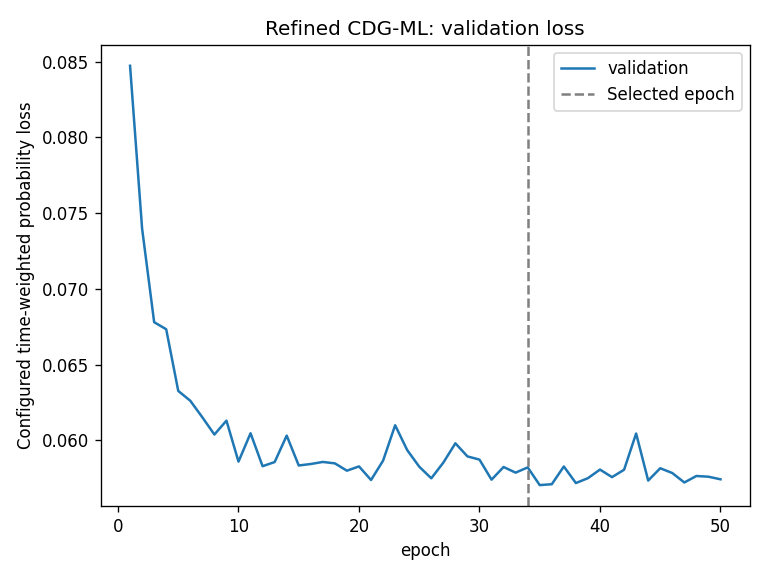

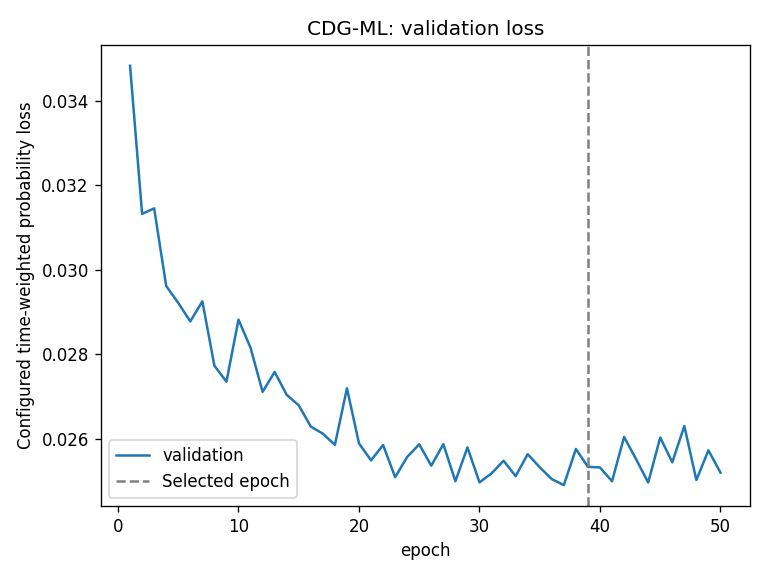

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.024520,0.025074
Constant-probability Brier loss,0.043431,0.043431
First-layer Tanh saturation,0.243484,0.268484
Last-step probability RMSE,0.024554,0.109803
Last-step gradient relative RMSE,0.825694,0.979540
Last-step gradient cosine,0.975715,0.489073
Gradient states (n),9.000000,9.000000
Selected epoch,34.000000,39.000000
Selected optimizer step,20724.000000,23864.000000


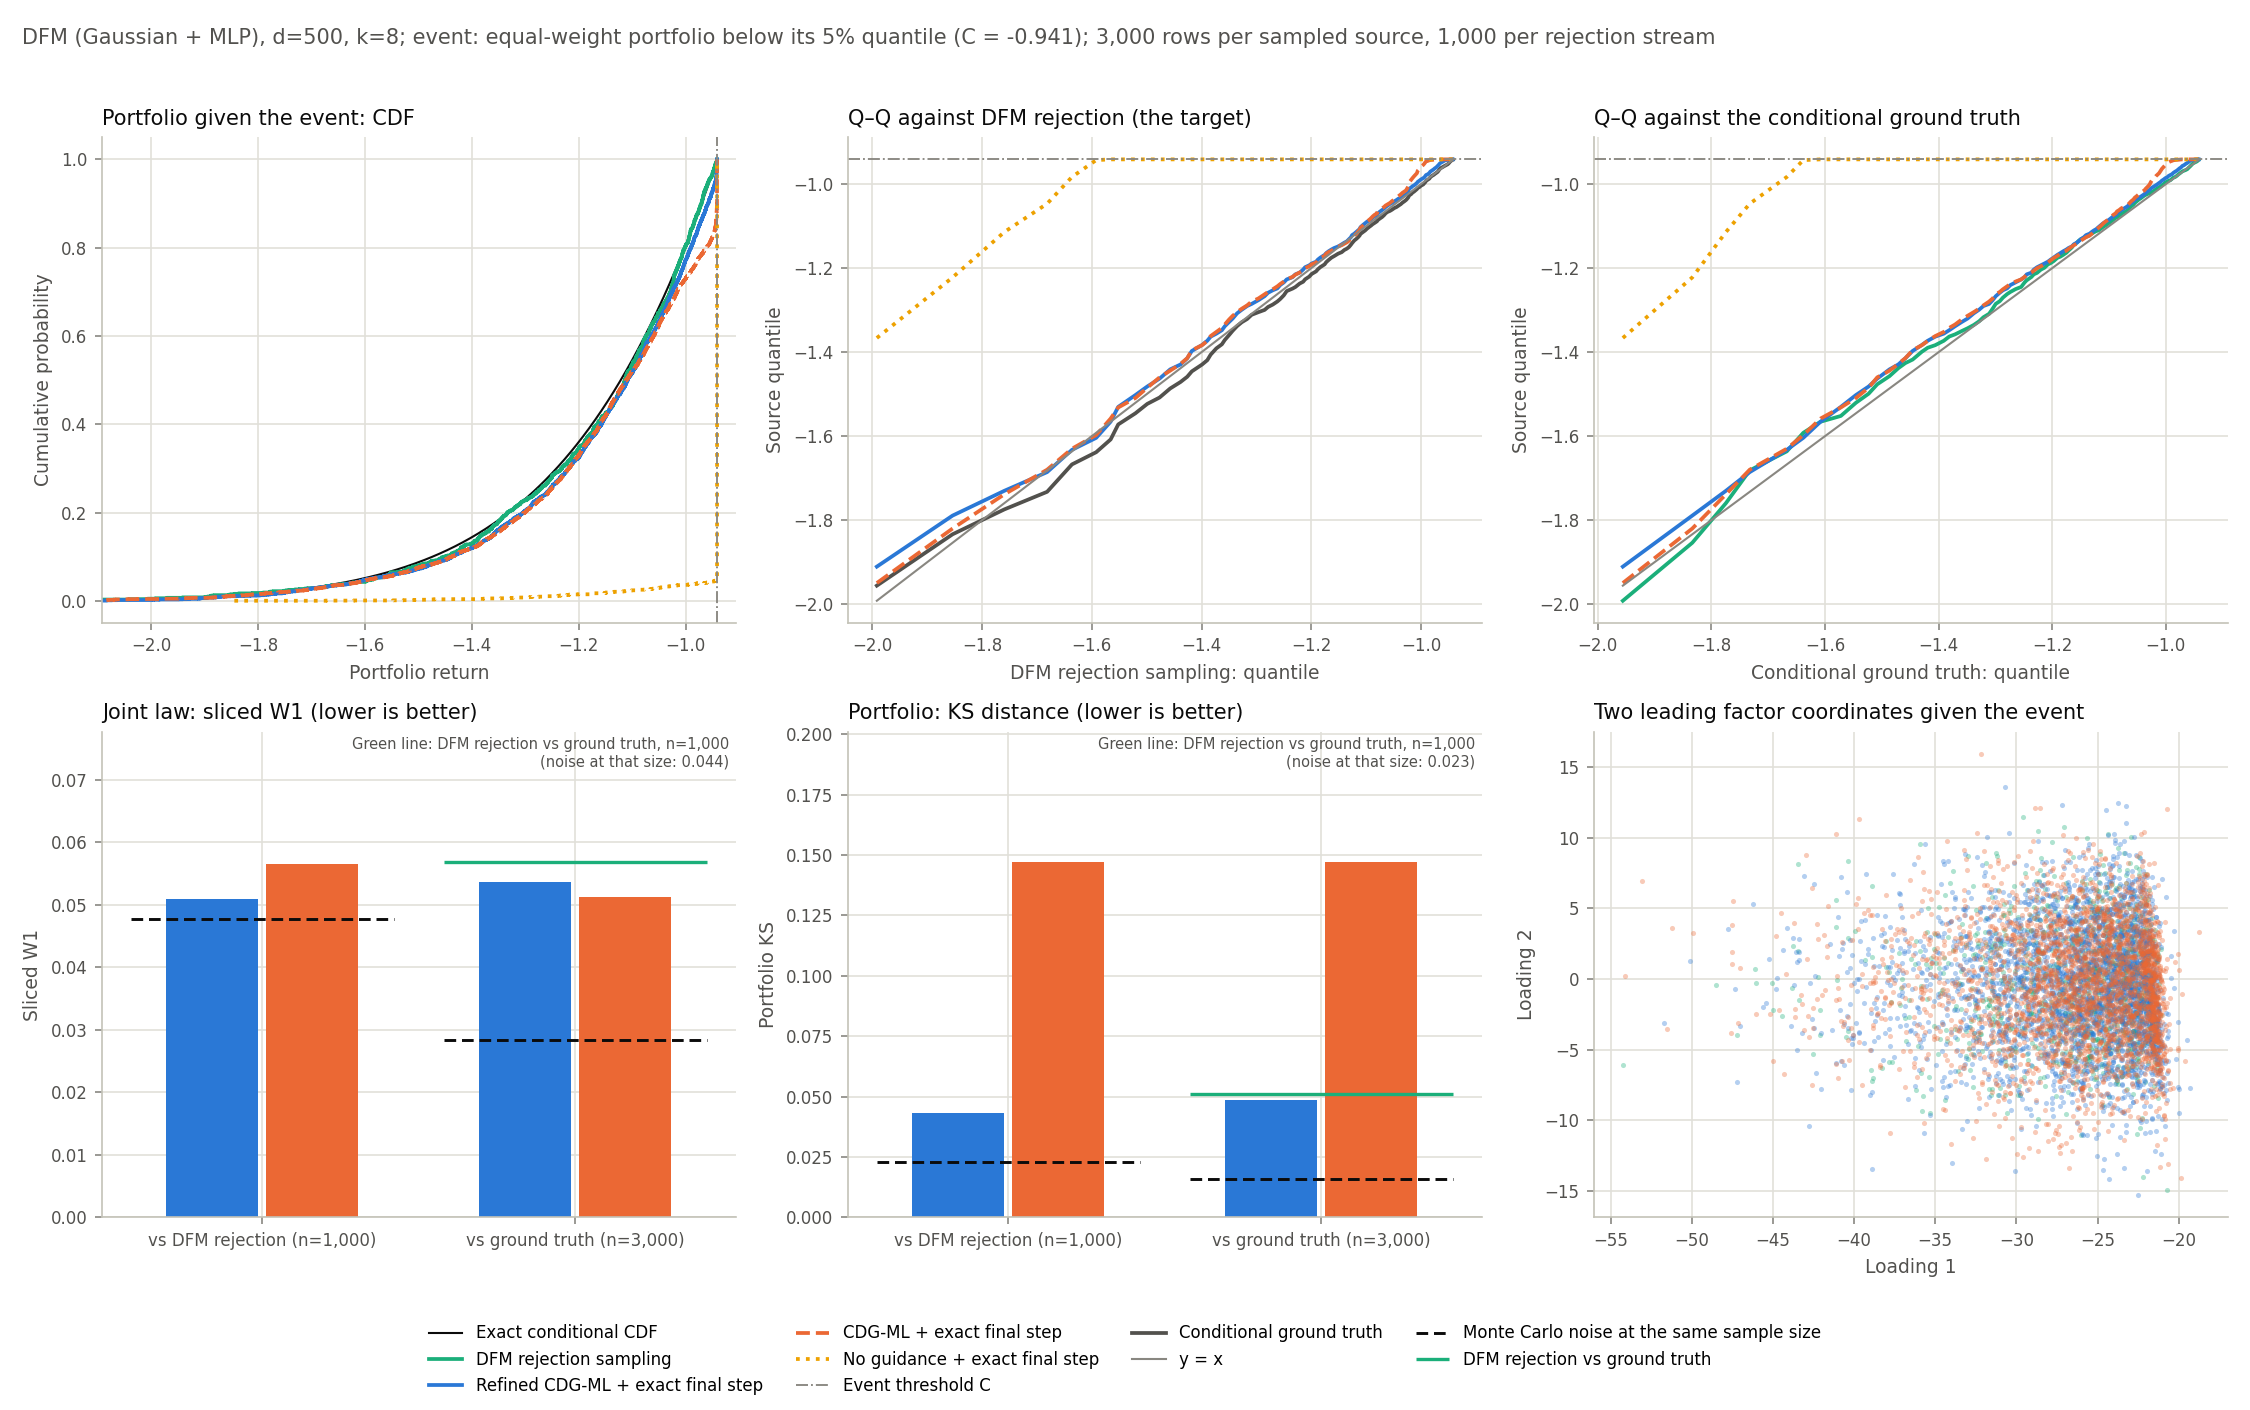

,Conditional ground truth,DFM rejection sampling,Refined CDG-ML + exact final step,CDG-ML + exact final step,No guidance + exact final step
Rows,3000.000000,1000.000000,3000.000000,3000.000000,3000.000000
Event rate,1.000000,1.000000,1.000000,1.000000,1.000000
Rows on the threshold,0.000000,0.000000,0.012667,0.096667,0.949000
Rows just below the threshold,0.064333,0.060000,0.104667,0.198000,0.958333
Portfolio KS vs DFM rejection,0.051000,0.023000,0.043000,0.147000,0.949000
Portfolio W1 vs DFM rejection,0.015533,0.005950,0.010845,0.022316,0.225708
Sliced W1 vs DFM rejection,0.056900,0.047783,0.050902,0.056554,0.235025
Rows compared vs DFM rejection,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
Portfolio KS vs ground truth,0.016000,0.051000,0.048667,0.147333,0.949000
Portfolio W1 vs ground truth,0.003114,0.015533,0.022419,0.028173,0.233832


Conditional benchmark saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T142439318443Z/conditional_tail0.05


In [12]:
conditional_5 = run_conditional_benchmark(
    GAUSSIAN_MLP_CONFIG, OUTPUT, tail=0.05, **H_RECIPE,
    assessment_settings=rejection_assessment(0.05, REJECTION_ROWS, **ASSESSMENT),
)

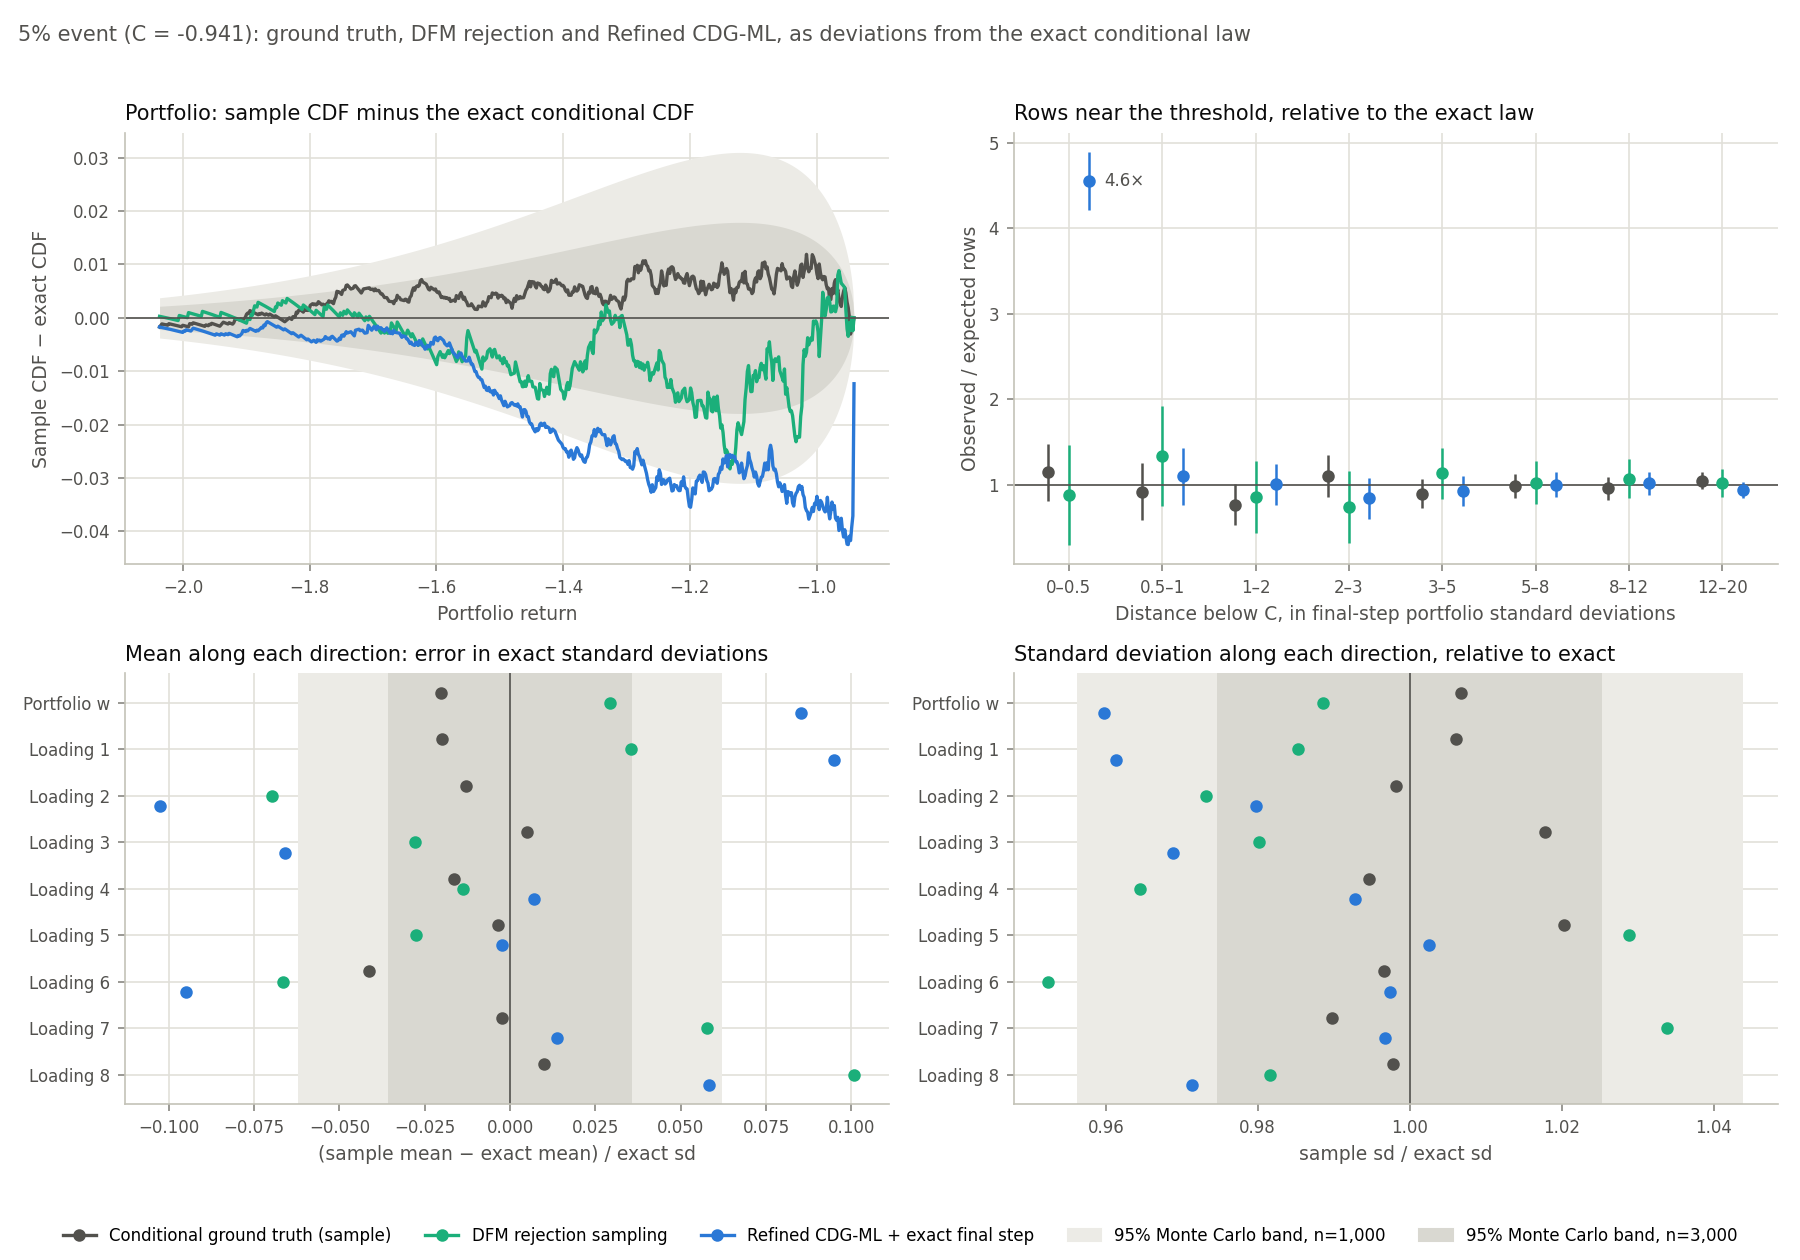

In [ ]:
from synthetic_benchmark.reporting import plot_refined_against_references

# Ground truth, DFM rejection and Refined CDG-ML only, each as its deviation from the exact
# conditional law, with 95% Monte Carlo bands at the same sample size.
closeup_5 = plot_refined_against_references(conditional_5, GAUSSIAN_MLP_CONFIG)

### The 1% event

Assets: 500; factors: 8; event probability 1%; frozen DFM (Gaussian + MLP), epoch 215


Event: equal-weight portfolio return <= -1.331004


Generating 40,000 train trajectories...


  Terminal event: 346/40,000 (0.86%)


Generating 2,000 validation trajectories...


  Terminal event: 17/2,000 (0.85%)


... (17 outputs left out)

DFM rejection stream 'rejection' (cap 400,000 proposals)...


  complete: 1,000/1,000 rows from 110,592 proposals in 961s


DFM rejection stream 'rejection_reference' (cap 400,000 proposals)...


  complete: 1,000/1,000 rows from 106,496 proposals in 940s


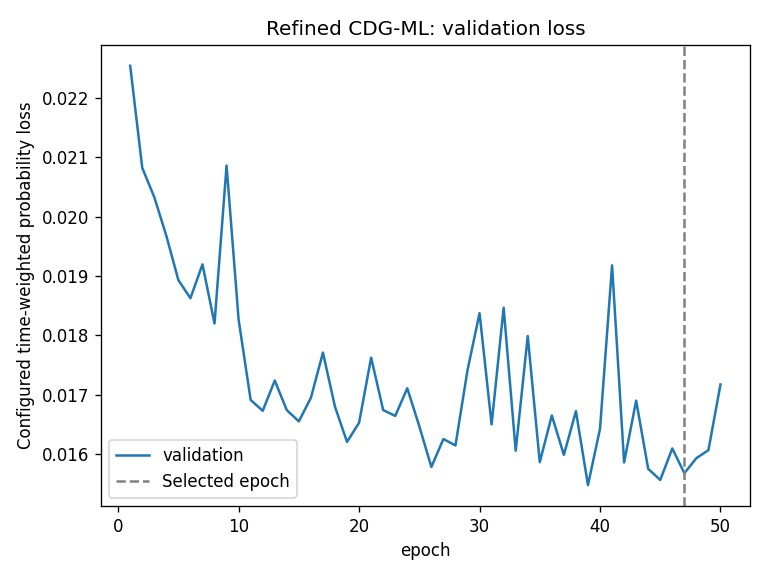

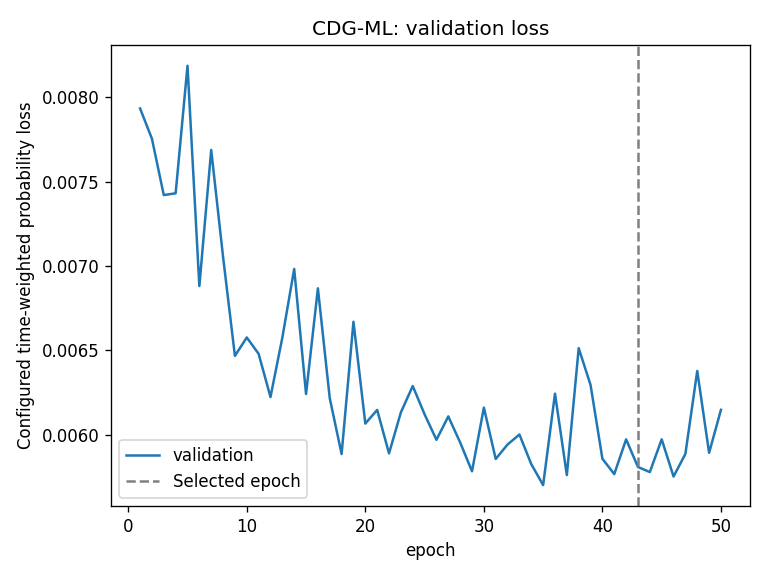

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.004908,0.005379
Constant-probability Brier loss,0.007936,0.007936
First-layer Tanh saturation,0.278430,0.333516
Last-step probability RMSE,0.026586,0.076620
Last-step gradient relative RMSE,0.964801,0.997605
Last-step gradient cosine,0.969543,0.362568
Gradient states (n),2.000000,2.000000
Selected epoch,47.000000,43.000000
Selected optimizer step,28888.000000,26533.000000


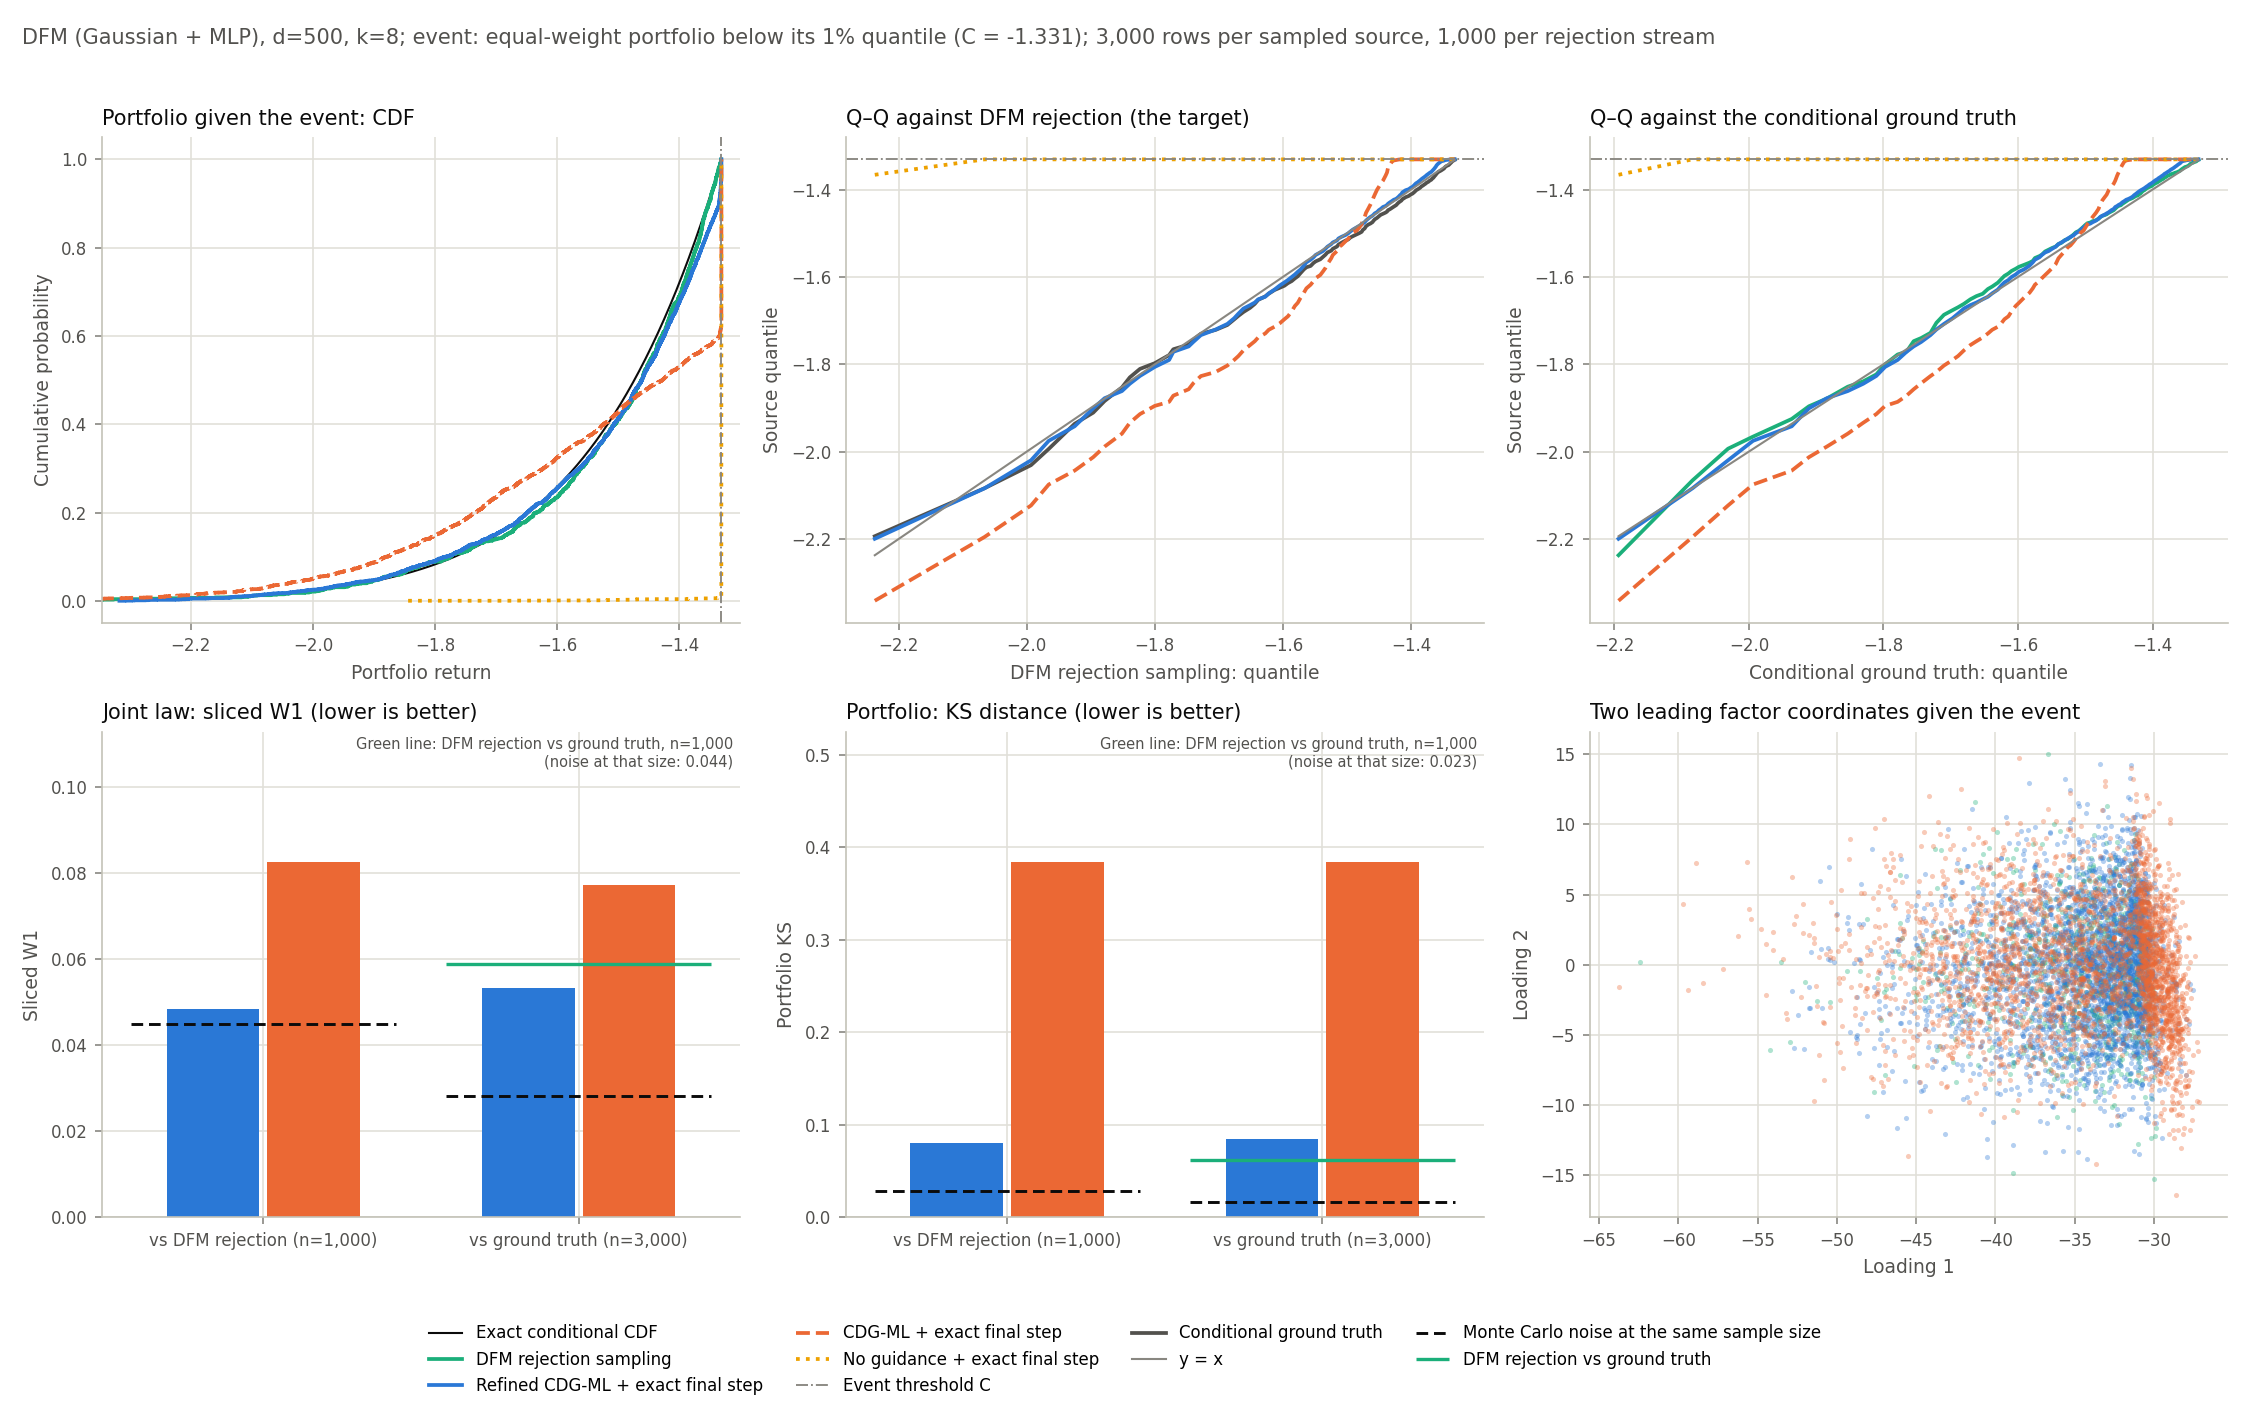

,Conditional ground truth,DFM rejection sampling,Refined CDG-ML + exact final step,CDG-ML + exact final step,No guidance + exact final step
Rows,3000.000000,1000.000000,3000.000000,3000.000000,3000.000000
Event rate,1.000000,1.000000,1.000000,1.000000,1.000000
Rows on the threshold,0.000000,0.000000,0.032667,0.362333,0.990667
Rows just below the threshold,0.081000,0.094000,0.154000,0.420667,0.994333
Portfolio KS vs DFM rejection,0.062000,0.028000,0.080000,0.384000,0.996000
Portfolio W1 vs DFM rejection,0.014834,0.008593,0.010177,0.065626,0.186576
Sliced W1 vs DFM rejection,0.058887,0.044811,0.048324,0.082667,0.265807
Rows compared vs DFM rejection,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
Portfolio KS vs ground truth,0.016000,0.062000,0.085000,0.384333,0.990667
Portfolio W1 vs ground truth,0.002624,0.014834,0.012728,0.059382,0.196488


Conditional benchmark saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T142439318443Z/conditional_tail0.01


In [13]:
conditional_1 = run_conditional_benchmark(
    GAUSSIAN_MLP_CONFIG, OUTPUT, tail=0.01, **H_RECIPE,
    assessment_settings=rejection_assessment(0.01, REJECTION_ROWS, **ASSESSMENT),
)

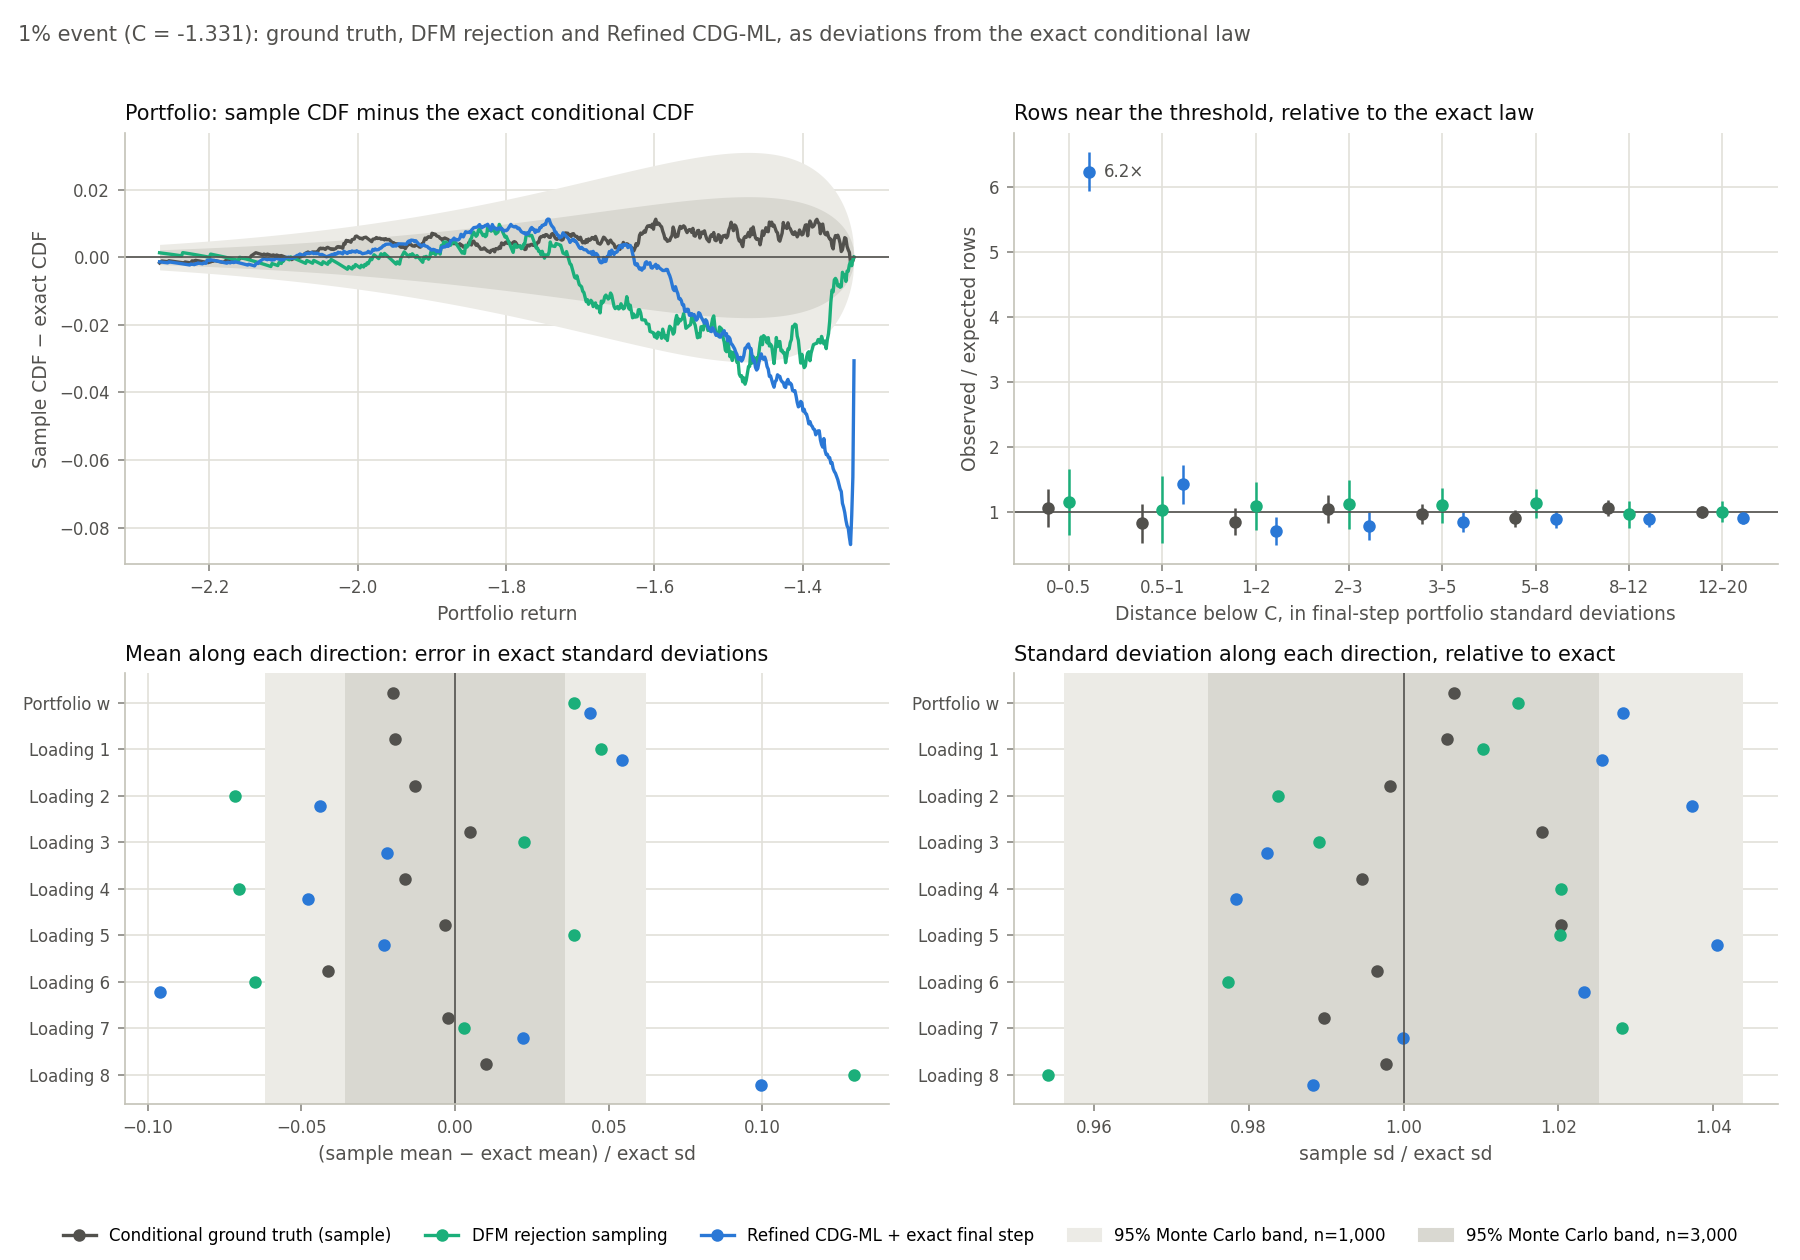

In [ ]:
from synthetic_benchmark.reporting import plot_refined_against_references

# Ground truth, DFM rejection and Refined CDG-ML only, each as its deviation from the exact
# conditional law, with 95% Monte Carlo bands at the same sample size.
closeup_1 = plot_refined_against_references(conditional_1, GAUSSIAN_MLP_CONFIG)

### Exact conditional moments


In [14]:
for results in (conditional_5, conditional_1):
    print(f"Event probability {results['tail']:.0%}:")
    display(results["moments"].round(4))
print("Saved with the samples, comparisons and figures under:", OUTPUT)

Event probability 5%:


,source,n,mean_error,covariance_error,diversity_trace_ratio,analytic_portfolio_ks
0,truth,3000,0.0150,0.1791,1.0013,0.0126
1,rejection,1000,0.0487,0.3281,1.0099,0.0291
2,refined_exact,3000,0.0503,0.2135,1.0066,0.0435
3,cdg_ml_exact,3000,0.0559,0.2298,1.0083,0.1474
4,unguided_exact,3000,0.3489,0.6560,0.9674,0.9490
5,truth_reference,3000,0.0149,0.1860,1.0008,0.0117
6,rejection_reference,1000,0.0481,0.3294,1.0114,0.0145


Event probability 1%:


,source,n,mean_error,covariance_error,diversity_trace_ratio,analytic_portfolio_ks
0,truth,3000,0.0148,0.1988,1.0010,0.0126
1,rejection,1000,0.0549,0.3690,1.0178,0.0379
2,refined_exact,3000,0.0509,0.2668,1.0248,0.0856
3,cdg_ml_exact,3000,0.0906,0.7343,1.0792,0.3855
4,unguided_exact,3000,0.3889,0.6009,0.9830,0.9907
5,truth_reference,3000,0.0147,0.2056,0.9998,0.0117
6,rejection_reference,1000,0.0595,0.3685,1.0051,0.0416


Saved with the samples, comparisons and figures under: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T142439318443Z


## Reading the current results

The tables and figures above report the current execution: the two unconditional DFMs,
then the five conditional sources at the 5% and 1% events. The final cell prints the
run's artifact folder. Check its saved configuration and completion status before
interpreting a run; conditional results from an earlier checkpoint are not results
of the current execution.

Compare each distance with its Monte Carlo level at the same sample size. Agreement
on sliced W1 does not by itself establish agreement on the portfolio margin, at either
the 5% or the 1% event: inspect
the CDF, Q–Q plots, portfolio KS, and concentration near the threshold as well. An
exact final step ensures event satisfaction up to rounding, but it does not ensure
the correct conditional distribution. Compare the no-guidance source with the two
H models to assess this distinction.
Describe agreement for the particular metric and reference used; a near-noise sliced
W1 can coexist with portfolio KS above its Monte Carlo level and excess mass near $C$.

**Limitations.**
* The standard configuration uses one DFM seed, one H initialization, and one stock cohort.
  A difference from an earlier run with another DFM checkpoint does not identify its cause.
* The Gaussian + MLP network is favored by the Gaussian population; this experiment
  tests the conditioning mechanism, rather than realistic heavy-tailed returns.
* The five refinements are applied together, so their individual effects are not isolated.
* Runtime and any break-even cost depend on the machine, event frequency, and requested
  number of scenarios. Use the current run's recorded timings.

See [METHODS.md](METHODS.md) for the derivations and interpretation of these comparisons.
